# Métricas de la trivia — Robot Romeo (perfil OPTIMISTA)
**Sesión 11 nov 2026 · perfil optimista (empatía 0.4, base (0.40, 0.30, 0.20)) · captura con `ROMEO_MEDIR=1`**

Solo métricas de la **trivia** (primeras 33 preguntas). Este notebook lee los CSV crudos y genera las gráficas.

**Novedad de esta sesión:** los tiempos de **STT, SER y TER** se miden **por separado en la propia Raspberry**
(archivo `percepcion.csv`), ya no en el PC. Cada turno guarda `t_stt_ms`, `t_ser_ms`, `t_ter_ms` e `ida_vuelta_ms`.

**Nodos del sistema:** `communication_node` (STT+TTS) · `expression_faces_node` (FER+caras) · `moving_control_node` (carrito) · `orchestrator_node` (afectiva PULSE/ROSE/AEB + LLM + trivia).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": "DejaVu Sans",
})
GRIS="#2b3a52"; VERDE="#1ba378"; NARANJA="#e07a1a"; AZUL="#2a78d6"; ROJO="#c0392b"; MORADO="#6a5aa0"

BASE = Path(r".")   # misma carpeta del notebook
def ruta(n): return BASE / n
N_PREGUNTAS = 33   # la sesion de trivia: primeras 33 preguntas

## 0. Reconstrucción del flujo completo desde el log (desde cero)

Antes de nada, se **reconstruye cada turno leyendo el `romeo_run.log` de inicio
a fin**, siguiendo el flujo real desde que el micro captura hasta que la IA
responde, y midiendo cada etapa con los **timestamps del propio log**:

```
[mic] transcrito → STT → TER + FER + SER → fusión (PULSE) → ROSE → AEB → Asistente responde
```

El tiempo del **STT** no está en el log (solo "[mic] transcrito"), pero sí en
`percepcion.csv` (medido en la Pi); se empareja por el texto de la frase, y por
orden si el texto difiere. Así cada métrica queda alineada a su turno real.

In [2]:
import re, csv as _csv
def reconstruir(log_txt, percep_path):
    """Devuelve una lista de turnos con sus tiempos por etapa, desde el log."""
    TS = re.compile(r"\[(\d+\.\d+)\]")
    def ts(l):
        m = TS.search(l); return float(m.group(1)) if m else None
    # percepcion.csv: STT/SER/TER por texto + en orden
    percep, percep_orden = {}, []
    with open(percep_path, encoding="utf-8", errors="replace") as f:
        for row in _csv.DictReader(f):
            txt = (row.get("texto") or "").strip().lower()[:30]
            if txt:
                percep[txt] = row; percep_orden.append(row)
    turnos = []; cur = None
    for ln in log_txt.splitlines():
        t = ts(ln)
        if t is None: continue
        if "[mic] transcrito:" in ln:
            m = re.search(r"transcrito: \'(.*)\'", ln)
            texto = (m.group(1) if m else "").strip()
            if not texto: cur = None; continue
            cur = {"t_mic": t, "texto": texto}; turnos.append(cur)
        elif cur is None: continue
        elif "[afecto] el texto expresa" in ln: cur["t_ter"] = t
        elif "[afecto] la camara vio" in ln:
            cur["t_fer"] = t
            mm = re.search(r"(\d+) cuadros en ([\d.]+) s", ln)
            if mm: cur["fer_ventana_s"] = float(mm.group(2))
        elif "[afecto] la voz suena" in ln: cur["t_ser"] = t
        elif "[afecto] usuario (fusion" in ln: cur["t_pulse"] = t
        elif re.search(r"\[afecto\] v .*->.*", ln): cur["t_rose"] = t
        elif "[aeb]" in ln and "t_aeb" not in cur:
            cur["t_aeb"] = t
            mm = re.search(r"-> (\w+_L\d|\w+) \(cara (\w+), movimiento (\w+)", ln)
            if mm:
                cur["emocion"], cur["cara"], cur["movimiento"] = mm.group(1), mm.group(2), mm.group(3)
        elif "Asistente:" in ln and "Asistente [" not in ln:
            cur["t_resp"] = t; cur = None
    # tiempos por etapa
    def num(v):
        try: return float(v)
        except (TypeError, ValueError): return np.nan
    out = []
    for i, tu in enumerate(turnos, 1):
        p = percep.get(tu["texto"].strip().lower()[:30])
        if p is None: p = percep_orden[i-1] if i-1 < len(percep_orden) else {}
        capa = (tu["t_aeb"]-tu["t_ter"])*1000 if "t_ter" in tu and "t_aeb" in tu else np.nan
        lat  = (tu["t_resp"]-tu["t_mic"])*1000 if "t_resp" in tu else np.nan
        out.append({"turno": i, "texto": tu["texto"][:40],
                    "stt_ms": num(p.get("t_stt_ms")), "ser_ms": num(p.get("t_ser_ms")),
                    "ter_ms": num(p.get("t_ter_ms")),
                    "capa_afectiva_ms": round(capa,1) if capa==capa else np.nan,
                    "fer_ventana_s": tu.get("fer_ventana_s", np.nan),
                    "latencia_ms": round(lat,1) if lat==lat else np.nan,
                    "emocion": tu.get("emocion",""), "cara": tu.get("cara",""),
                    "movimiento": tu.get("movimiento","")})
    return pd.DataFrame(out)

log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
rec = reconstruir(log, ruta("percepcion.csv"))
rec.to_csv(ruta("turnos_reconstruidos.csv"), index=False)
print(f"Turnos reconstruidos desde el log: {len(rec)}")
print(rec[["turno","stt_ms","ser_ms","ter_ms","capa_afectiva_ms","fer_ventana_s","latencia_ms","emocion"]].head(10).to_string(index=False))

Turnos reconstruidos desde el log: 50
 turno  stt_ms  ser_ms  ter_ms  capa_afectiva_ms  fer_ventana_s  latencia_ms      emocion
     1    23.3   187.8    26.8               NaN            0.6        254.7             
     2    50.1    14.5    14.3              25.3            2.5        244.6 felicidad_L1
     3    30.1   120.7    16.2              22.8            1.2        521.4 felicidad_L1
     4    54.9   261.3    16.9              52.9            2.8        266.9   neutral_L0
     5    30.4   117.1    13.0              19.2            1.1        444.5 felicidad_L1
     6    53.0   273.4    13.7              20.1            2.8        239.1 felicidad_L1
     7    27.8   116.3    26.7              20.5            1.1        527.2 felicidad_L2
     8    26.7   222.7    15.7              23.6            1.0        217.9 felicidad_L2
     9   381.1   360.0    39.9              21.1           20.2        293.0 felicidad_L1
    10    89.5   218.0    23.2              19.2            5.

In [3]:
# Resumen del flujo completo reconstruido (promedios por etapa).
resumen = pd.DataFrame([
    ("STT (voz→texto)",        rec["stt_ms"].mean(),           "ms"),
    ("SER (emoción voz)",      rec["ser_ms"].mean(),           "ms"),
    ("TER (emoción texto)",    rec["ter_ms"].mean(),           "ms"),
    ("Capa afectiva (PULSE+ROSE+AEB)", rec["capa_afectiva_ms"].mean(), "ms"),
    ("Ventana FER (cámara)",   rec["fer_ventana_s"].mean(),    "s"),
    ("Latencia total (mic→IA)",rec["latencia_ms"].mean(),      "ms"),
], columns=["Etapa del flujo", "Promedio", "Unidad"])
resumen["Promedio"] = resumen["Promedio"].round(1)
print("Flujo completo del turno, medido desde el log:")
resumen

Flujo completo del turno, medido desde el log:


,Etapa del flujo,Promedio,Unidad
0,STT (voz→texto),81.7,ms
1,SER (emoción voz),203.2,ms
2,TER (emoción texto),20.0,ms
3,Capa afectiva (PULSE+ROSE+AEB),33.6,ms
4,Ventana FER (cámara),4.5,s
5,Latencia total (mic→IA),502.3,ms


## 1. Cargar los datos

In [4]:
# La trivia empieza en la PRIMERA pregunta que hace Romeo (Asistente [emo]: ...?).
import re
INICIO_TRIVIA = 0.0
log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
m = re.search(r"\[(\d+\.\d+)\].*Vamos con una trivia", log)
if not m:
    m = re.search(r"\[(\d+\.\d+)\].*Asistente \[[^\]]+\]: [^\n]*\?", log)
if m: INICIO_TRIVIA = float(m.group(1))
print("La trivia empieza en t =", INICIO_TRIVIA)

La trivia empieza en t = 1794441925.3833537


In [5]:
# turnos (Pi): afectiva + LLM + tokens + emocion + movimiento, SOLO desde la trivia.
# Algunas filas vienen con una columna extra, por eso se parsea por el campo t_fin (>1e9).
filas = []
with open(ruta("turnos.csv"), encoding="utf-8", errors="replace") as f:
    next(f)
    for ln in f:
        partes = ln.rstrip("\n").split(",")
        nums = []
        for x in partes:
            try: nums.append(float(x))
            except ValueError: pass
        ei = next((i for i,v in enumerate(nums) if v > 1e9), None)  # t_fin
        if ei is None or ei < 3: continue
        t_fin = nums[ei]
        if t_fin < INICIO_TRIVIA: continue
        afect = nums[0]*1000          # t_pulse_rose (s -> ms)
        t_llm = nums[ei-1]            # t_llm (ms)
        tok   = nums[ei-3]            # llm_tokens_salida
        # emocion y movimiento: las dos columnas de texto antes del ultimo texto
        emocion = partes[-3].strip() if len(partes) >= 3 else ""
        movimiento = partes[-2].strip() if len(partes) >= 2 else ""
        if 50 <= t_llm <= 6000 and 1 <= tok <= 300:
            # La capa afectiva SIEMPRE se calcula (se quito la regla de saltarla
            # con todo neutral). Se muestran los 33 turnos sin recorte; el tiempo
            # incluye la espera de la ventana de camara antes de fusionar, por eso
            # algunos turnos son altos.
            filas.append({"afectiva_ms": afect,
                          "t_llm_ms": t_llm, "tokens_salida": tok,
                          "emocion": emocion, "movimiento": movimiento})
turnos = pd.DataFrame(filas[:N_PREGUNTAS])

# percepcion (Pi): STT / SER / TER por separado + ida_vuelta.
# Solo cuentan los turnos donde el usuario REALMENTE habla: se descartan las
# filas sin texto (micro activado por ruido/silencio, sin SER/TER). Asi cada
# punto es una respuesta real del usuario y no quedan huecos.
per = pd.read_csv(ruta("percepcion.csv"))
per = per[per["texto"].notna() & (per["texto"].astype(str).str.strip() != "")]
per_triv = per[per["t"] >= INICIO_TRIVIA].head(N_PREGUNTAS).reset_index(drop=True)

tts = pd.read_csv(ruta("tts.csv"))
sis = pd.read_csv(ruta("sistema.csv"))
sis["min"] = (sis["t"] - sis["t"].iloc[0]) / 60
print("turnos:", len(turnos), "| percepcion trivia:", len(per_triv),
      "| tts:", len(tts), "| sistema:", len(sis))

turnos: 33 | percepcion trivia: 33 | tts: 85 | sistema: 609


## 2. Comparación Rocha vs IA  —  ¿coincide la respuesta?

Para cada pregunta de la trivia se comparó la **respuesta del usuario** con la
**respuesta esperada** (banco de Rocha); el veredicto lo dio el corrector LLM
de Romeo (registrado en el log). Aquí se cuenta por categoría temática.
**Recalculado desde el log de esta sesión: 19/33 = 58 %.**

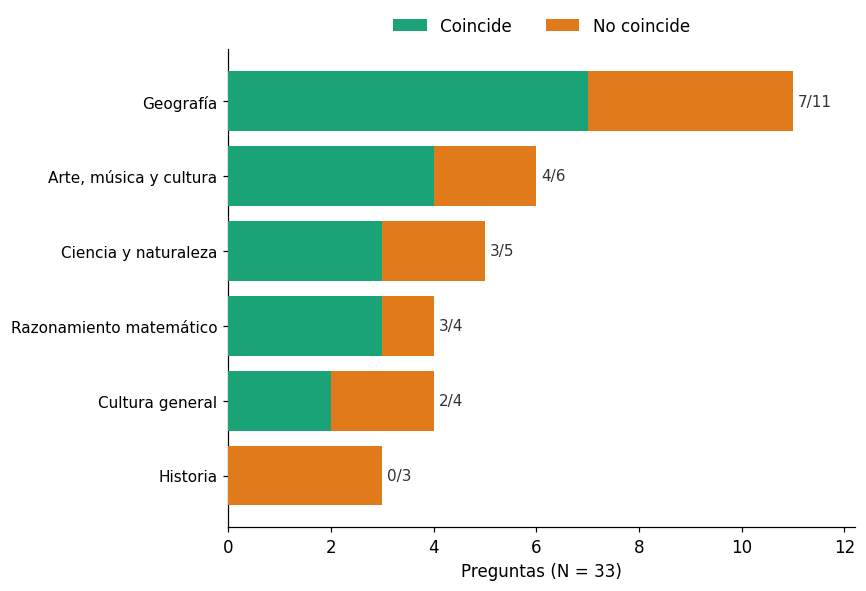

Coincidencia Rocha vs IA: 19/33 = 58%


In [6]:
# Aciertos/total por categoria, recalculados desde los veredictos del log (sesion optimista).
cats = [
    ("Geografía", 7, 11),
    ("Arte, música y cultura", 4, 6),
    ("Ciencia y naturaleza", 3, 5),
    ("Razonamiento matemático", 3, 4),
    ("Cultura general", 2, 4),
    ("Historia", 0, 3),
]
dfc = pd.DataFrame(cats, columns=["categoria","coincide","total"])
dfc["no_coincide"] = dfc["total"] - dfc["coincide"]
dfc = dfc.iloc[::-1].reset_index(drop=True)  # mayor arriba

fig, ax = plt.subplots(figsize=(8,5.5))
y = np.arange(len(dfc))
ax.barh(y, dfc["coincide"], color=VERDE, zorder=3, label="Coincide")
ax.barh(y, dfc["no_coincide"], left=dfc["coincide"], color=NARANJA, zorder=3, label="No coincide")
for i,(c,t) in enumerate(zip(dfc["coincide"], dfc["total"])):
    ax.text(t+0.1, i, f"{c}/{t}", va="center", fontsize=10, color="#333")
ax.set_yticks(y); ax.set_yticklabels(dfc["categoria"], fontsize=10)
co, to = dfc["coincide"].sum(), dfc["total"].sum()
ax.set_xlabel(f"Preguntas (N = {to})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,1.10), ncol=2, frameon=False, fontsize=11)
ax.set_xlim(0, dfc["total"].max()+1.2)
plt.tight_layout(); plt.show()
print(f"Coincidencia Rocha vs IA: {co}/{to} = {100*co/to:.0f}%")

## 3. Datos por turno

Se arma la tabla con el tiempo de cada etapa en cada pregunta. **STT, SER y TER
se toman directamente de `percepcion.csv`** (medidos en la Pi, por turno, por
separado). El resto (afectiva, LLM, tokens, emoción, movimiento) viene de
`turnos.csv`; TTS de `tts.csv`; la ventana FER se lee del log.

In [7]:
import re
# Ventana FER por turno, EMPAREJADA POR TIEMPO. El log tiene mas lineas "FER:"
# que preguntas (la camara cierra varias ventanas por turno), asi que NO sirve
# el orden ciego. El patron real de cada turno es:
#   [mic] transcrito  ->  Asistente: (respuesta)  ->  FER: X cuadros en Y s
# Se toma la ventana FER que aparece justo DESPUES de cada transcripcion del
# usuario (la que corresponde a mientras el usuario hablaba ese turno).
eventos = []
for ln in log.splitlines():
    m = re.search(r"\[(\d+\.\d+)\]", ln)
    if not m: continue
    t = float(m.group(1))
    if "[mic] transcrito:" in ln:
        mm = re.search(r"transcrito: '(.*)'", ln)
        txt = (mm.group(1) if mm else "").strip()
        if txt:                       # solo turnos reales (con texto)
            eventos.append((t, "MIC"))
    elif "FER:" in ln:
        mm = re.search(r"FER: \d+ cuadros en ([\d.]+) s", ln)
        if mm: eventos.append((t, "FER", float(mm.group(1))*1000))
# para cada MIC, la primera ventana FER que viene despues
fer_vent = []
for i, ev in enumerate(eventos):
    if ev[1] != "MIC": continue
    sig = next((e for e in eventos[i+1:] if e[1] == "FER"), None)
    if sig: fer_vent.append(sig[2])
# TTS por turno (en orden; tts.csv no trae texto)
tts_vals = pd.to_numeric(tts["t_tts_ms"], errors="coerce").dropna().tolist()

n = min(N_PREGUNTAS, len(turnos), len(per_triv))
dft = pd.DataFrame({
    "pregunta": range(1, n+1),
    "STT": per_triv["t_stt_ms"].iloc[:n].values,
    "SER": per_triv["t_ser_ms"].iloc[:n].values,
    "TER": per_triv["t_ter_ms"].iloc[:n].values,
    "ida_vuelta": per_triv["ida_vuelta_ms"].iloc[:n].values,
    "afectiva": turnos["afectiva_ms"].iloc[:n].values,
    "LLM": turnos["t_llm_ms"].iloc[:n].values,
    "emocion": turnos["emocion"].iloc[:n].values,
    "movimiento": turnos["movimiento"].iloc[:n].values,
})
dft["TTS"] = [tts_vals[i] if i < len(tts_vals) else np.nan for i in range(n)]
dft["FER"] = [fer_vent[i] if i < len(fer_vent) else np.nan for i in range(n)]
# por nodo
dft["communication_node"] = dft[["STT","TTS"]].sum(axis=1, min_count=1)
dft["orchestrator_node"]  = dft[["afectiva","LLM"]].sum(axis=1, min_count=1)
dft["expression_faces_node"] = dft["FER"]
print(f"{len(dft)} turnos."); dft.head(10)

33 turnos.


,pregunta,STT,SER,TER,ida_vuelta,afectiva,LLM,emocion,movimiento,TTS,FER,communication_node,orchestrator_node,expression_faces_node
0,1,94.2,274.5,24.7,471.4,3700.0,489.0,felicidad_L1,ninguno,1523.6,87600.0,1617.8,4189.0,87600.0
1,2,132.9,194.4,26.2,462.7,3400.0,552.2,felicidad_L1,ninguno,1618.2,34900.0,1751.1,3952.2,34900.0
2,3,106.9,304.2,17.2,502.2,5400.0,379.4,felicidad_L1,ninguno,1429.6,10500.0,1536.5,5779.4,10500.0
3,4,51.2,174.0,17.9,314.5,13800.0,387.6,felicidad_L1,ninguno,1518.1,26800.0,1569.3,14187.6,26800.0
4,5,89.5,235.4,20.3,415.4,5700.0,379.5,felicidad_L1,ninguno,1012.8,15500.0,1102.3,6079.5,15500.0
5,6,81.0,187.5,20.6,367.1,6200.0,649.1,felicidad_L1,ninguno,1263.0,21100.0,1344.0,6849.1,21100.0
6,7,92.3,222.1,22.9,401.6,3900.0,556.1,felicidad_L1,ninguno,1270.6,239200.0,1362.9,4456.1,239200.0
7,8,27.7,112.9,19.5,195.7,6900.0,745.0,felicidad_L1,ninguno,1162.4,4800.0,1190.1,7645.0,4800.0
8,9,57.7,183.2,15.2,308.1,26300.0,441.8,felicidad_L1,ninguno,1171.6,24600.0,1229.3,26741.8,24600.0
9,10,25.5,116.0,13.1,188.4,12500.0,656.0,felicidad_L1,ninguno,2057.1,55700.0,2082.6,13156.0,55700.0


## 4. STT, SER y TER por turno — medidos en la Raspberry

Los tres tiempos de percepción del lenguaje/voz, capturados **por separado en la
propia Pi** (lo que pediste): **STT** (voz→texto), **SER** (emoción de la voz) y
**TER** (emoción del texto).

Como los tres tienen **escalas muy distintas** (el TER es ~15-25 ms, el SER
~200 ms y el STT ~80 ms), se grafican en **paneles separados, cada uno con su
propia escala**, para poder ver el procesamiento real de cada uno por pregunta.
Abajo va además la vista combinada con el viaje de ida y vuelta.

Solo se cuentan los turnos donde **el usuario realmente habla** (con texto
transcrito): las activaciones del micro sin habla se descartan, por eso no hay
huecos.

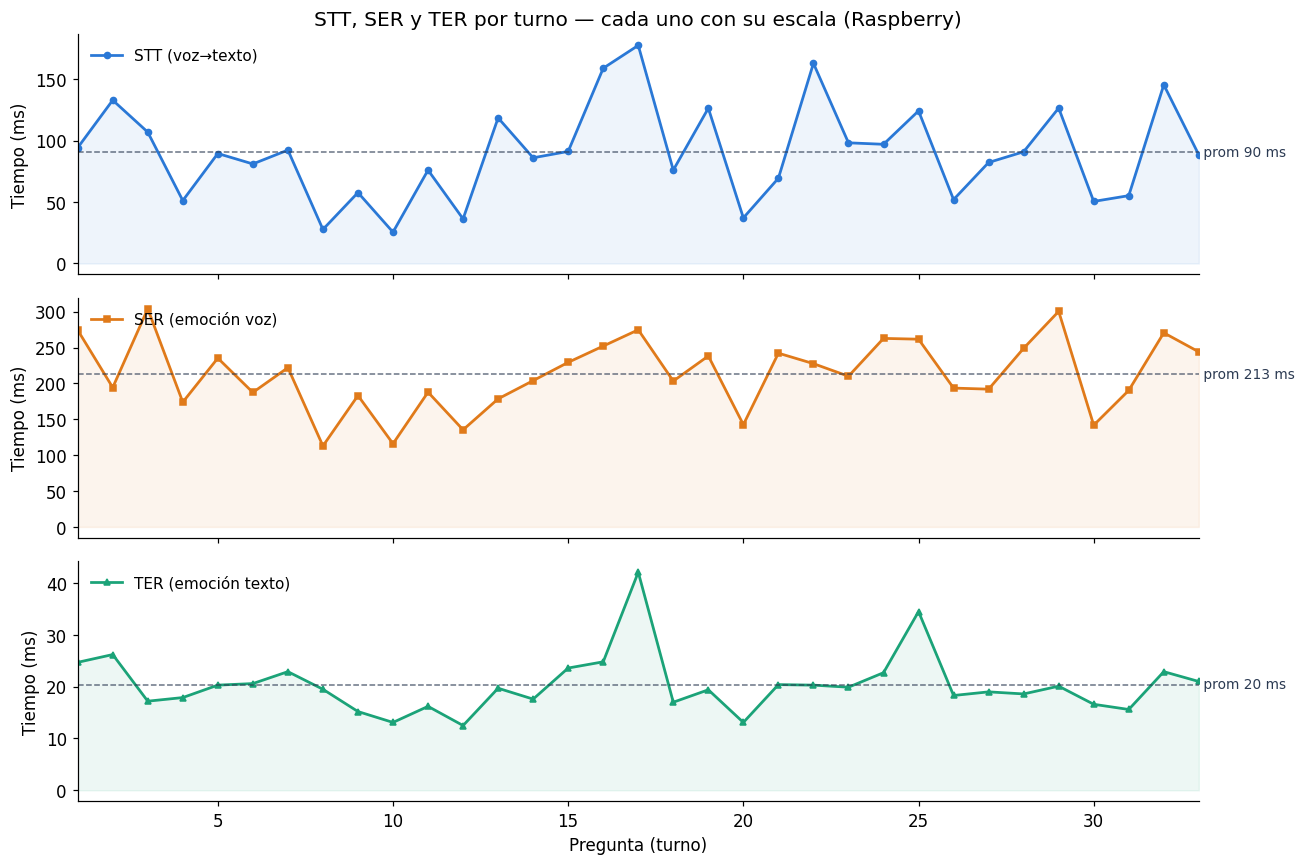

STT: 90 ms (min 26, max 178) | SER: 213 ms (min 113, max 304) | TER: 20 ms (min 12, max 42)


In [8]:
# Tres paneles, cada uno con su escala, para ver el detalle de cada etapa.
fig, axs = plt.subplots(3, 1, figsize=(12,8), sharex=True)
x = dft["pregunta"]
for ax, col, color, mk, nombre in [
    (axs[0], "STT", AZUL,    "o", "STT (voz→texto)"),
    (axs[1], "SER", NARANJA, "s", "SER (emoción voz)"),
    (axs[2], "TER", VERDE,   "^", "TER (emoción texto)"),
]:
    serie = dft[col]
    ax.plot(x, serie, color=color, lw=1.8, marker=mk, ms=4, label=nombre)
    prom = serie.mean()
    ax.axhline(prom, color=GRIS, ls="--", lw=1, alpha=0.7)
    ax.text(len(dft), prom, f" prom {prom:.0f} ms", va="center", fontsize=9, color=GRIS)
    ax.fill_between(x, 0, serie, color=color, alpha=0.08)
    ax.set_ylabel("Tiempo (ms)")
    ax.legend(loc="upper left", frameon=False, fontsize=10)
    ax.set_xlim(1, len(dft))
axs[2].set_xlabel("Pregunta (turno)")
axs[0].set_title("STT, SER y TER por turno — cada uno con su escala (Raspberry)")
plt.tight_layout(); plt.show()
print(f"STT: {dft['STT'].mean():.0f} ms (min {dft['STT'].min():.0f}, max {dft['STT'].max():.0f}) | "
      f"SER: {dft['SER'].mean():.0f} ms (min {dft['SER'].min():.0f}, max {dft['SER'].max():.0f}) | "
      f"TER: {dft['TER'].mean():.0f} ms (min {dft['TER'].min():.0f}, max {dft['TER'].max():.0f})")

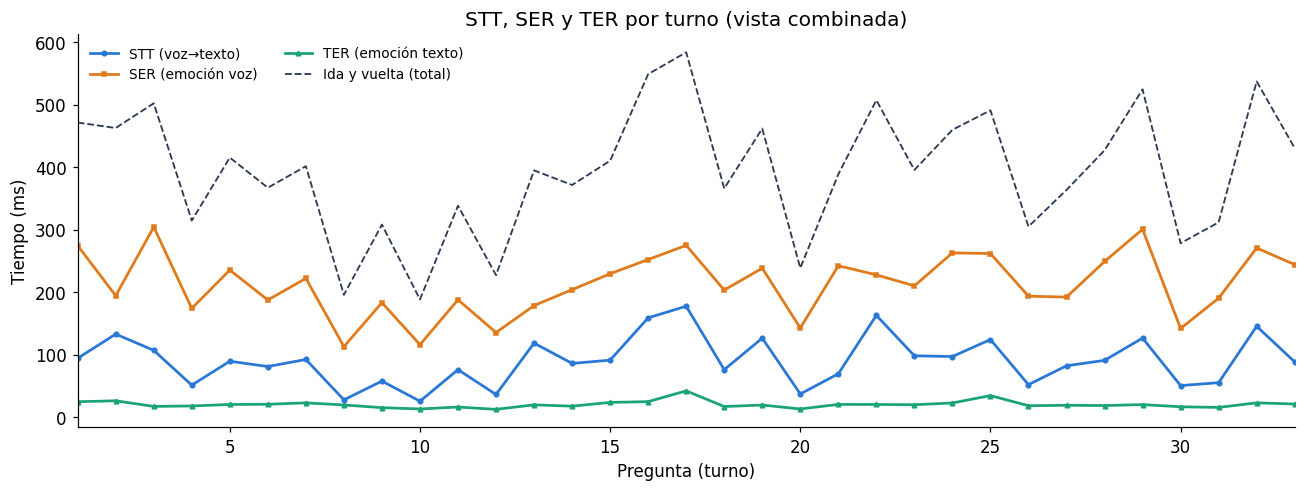

STT: 90 ms | SER: 213 ms | TER: 20 ms | Ida-vuelta: 394 ms (promedios)


In [9]:
# Vista combinada (misma escala) + viaje de ida y vuelta.
fig, ax = plt.subplots(figsize=(12,4.6))
x = dft["pregunta"]
ax.plot(x, dft["STT"], color=AZUL,    lw=1.8, marker="o", ms=3, label="STT (voz→texto)")
ax.plot(x, dft["SER"], color=NARANJA, lw=1.8, marker="s", ms=3, label="SER (emoción voz)")
ax.plot(x, dft["TER"], color=VERDE,   lw=1.8, marker="^", ms=3, label="TER (emoción texto)")
ax.plot(x, dft["ida_vuelta"], color=GRIS, lw=1.2, ls="--", label="Ida y vuelta (total)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_xlim(1, len(dft))
ax.set_title("STT, SER y TER por turno (vista combinada)")
ax.legend(frameon=False, fontsize=9, ncol=2)
plt.tight_layout(); plt.show()
print(f"STT: {dft['STT'].mean():.0f} ms | SER: {dft['SER'].mean():.0f} ms | "
      f"TER: {dft['TER'].mean():.0f} ms | Ida-vuelta: {dft['ida_vuelta'].mean():.0f} ms (promedios)")

## 5. Línea de tiempo por nodo

El tiempo de `expression_faces_node` es la **ventana de la cámara**: crece cuando
el usuario tarda en responder. Unos pocos turnos con pausas largas disparan ese
tiempo a decenas de segundos y aplastarían el resto, así que el eje se **recorta
a 60 s** y esos picos se **anotan con su valor real** (son pausas del usuario, no
lentitud del sistema).

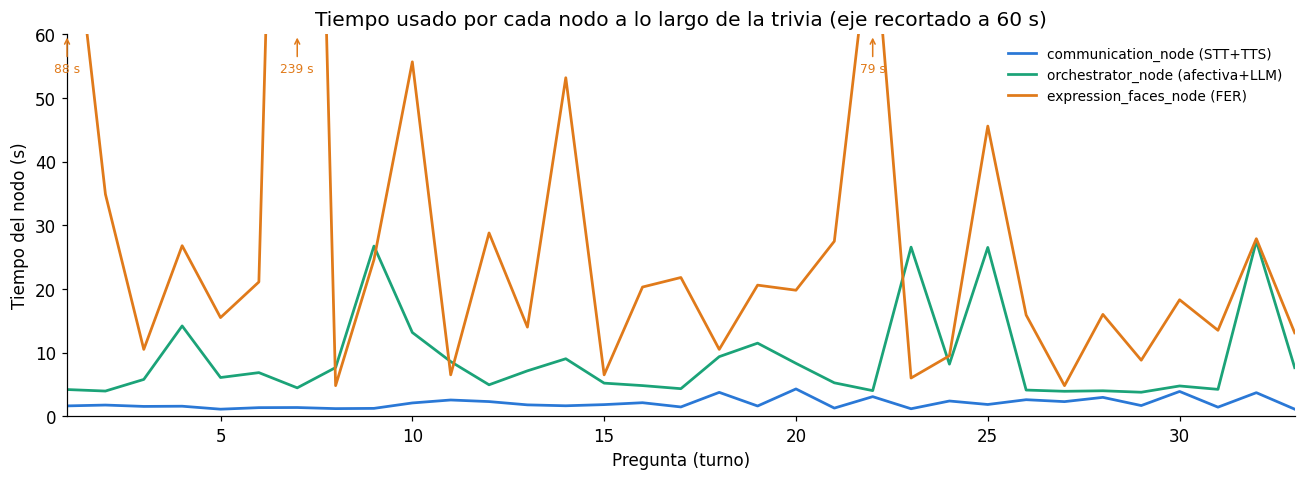

moving_control_node (carrito): no interviene en la trivia.
Picos de ventana FER (pausas largas del usuario): preg 1: 88s, preg 7: 239s, preg 22: 79s


In [10]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["communication_node"]/1000, color=AZUL, lw=1.8, label="communication_node (STT+TTS)")
ax.plot(x, dft["orchestrator_node"]/1000, color=VERDE, lw=1.8, label="orchestrator_node (afectiva+LLM)")
ax.plot(x, dft["expression_faces_node"]/1000, color=NARANJA, lw=1.8, label="expression_faces_node (FER)")
TOPE = 60  # segundos
ax.set_ylim(0, TOPE)
# anotar los picos que se salen del tope (pausas largas del usuario)
fer_s = dft["expression_faces_node"]/1000
for xi, v in zip(x, fer_s):
    if v > TOPE:
        ax.annotate(f"{v:.0f} s", xy=(xi, TOPE), xytext=(xi, TOPE*0.9),
                    ha="center", fontsize=8, color=NARANJA,
                    arrowprops=dict(arrowstyle="->", color=NARANJA, lw=1))
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo del nodo (s)")
ax.set_xlim(1, len(dft))
ax.set_title("Tiempo usado por cada nodo a lo largo de la trivia (eje recortado a 60 s)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("moving_control_node (carrito): no interviene en la trivia.")
picos = [(int(xi), float(v)) for xi, v in zip(x, fer_s) if v > TOPE]
print("Picos de ventana FER (pausas largas del usuario):",
      ", ".join(f"preg {p}: {s:.0f}s" for p, s in picos))

## 6. Latencia de respuesta por interacción (medida en la Raspberry)

Tiempo desde que el usuario termina de hablar hasta que Romeo responde, por cada
pregunta. Se mide en la Pi con los instantes del log (fin de transcripción →
inicio de la respuesta del asistente).

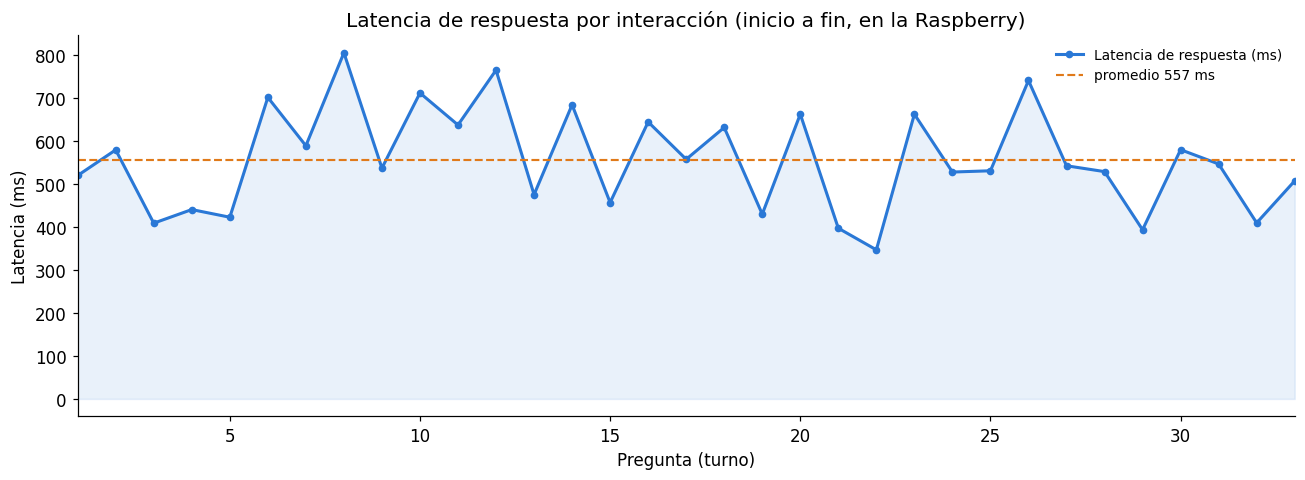

Latencia: promedio 557 ms, min 347, max 806 ms


In [11]:
latencias = []
t_mic = None
for ln in log.splitlines():
    m = re.search(r"\[(\d+\.\d+)\]", ln)
    if not m: continue
    ts = float(m.group(1))
    if "[mic] transcrito:" in ln:
        t_mic = ts
    elif "Asistente:" in ln and "Asistente [" not in ln and t_mic is not None and ts >= INICIO_TRIVIA:
        lat = (ts - t_mic) * 1000
        if 0 < lat < 30000:
            latencias.append(lat)
        t_mic = None
latencias = latencias[:N_PREGUNTAS]

fig, ax = plt.subplots(figsize=(12,4.5))
xx = range(1, len(latencias) + 1)
ax.plot(xx, latencias, color=AZUL, lw=2, marker="o", ms=4, label="Latencia de respuesta (ms)")
ax.axhline(np.mean(latencias), color=NARANJA, ls="--", lw=1.4,
           label=f"promedio {np.mean(latencias):.0f} ms")
ax.fill_between(xx, 0, latencias, color=AZUL, alpha=0.10)
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Latencia (ms)")
ax.set_xlim(1, len(latencias))
ax.set_title("Latencia de respuesta por interacción (inicio a fin, en la Raspberry)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print(f"Latencia: promedio {np.mean(latencias):.0f} ms, min {min(latencias):.0f}, max {max(latencias):.0f} ms")

## 7. Los tres modelos de percepción emocional: FER, SER y TER

Las tres fuentes que alimentan la capa afectiva, por turno:
- **FER** (emoción por la cara) — es la **ventana de la cámara**, en segundos;
  crece cuando el usuario tarda en responder.
- **SER** (emoción por la voz) y **TER** (emoción por el texto) — en milisegundos.

Como FER está en segundos y SER/TER en milisegundos, van en **paneles separados,
cada uno con su escala**. En el FER el eje se recorta a 60 s y las pausas largas
del usuario se anotan con su valor real.

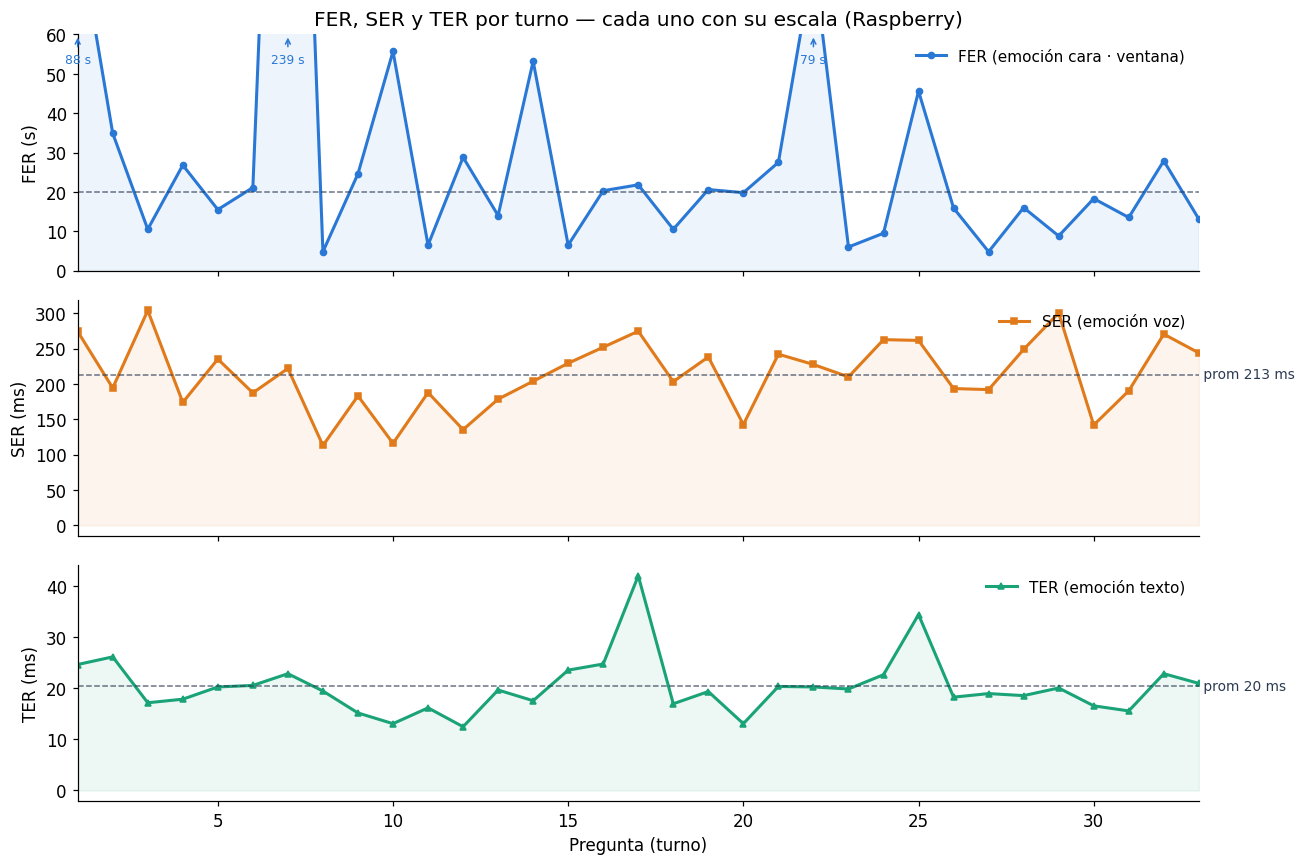

FER: promedio 30.6 s (max 239 s) | SER: 213 ms | TER: 20 ms
Picos FER (pausas largas del usuario): preg 1: 88s, preg 7: 239s, preg 22: 79s


In [12]:
fig, axs = plt.subplots(3, 1, figsize=(12,8), sharex=True)
x = dft["pregunta"]
fer_s = dft["FER"] / 1000.0

# (1) FER en segundos, recortado a 60s
TOPE = 60
axs[0].plot(x, fer_s, color=AZUL, lw=2, marker="o", ms=4, label="FER (emoción cara · ventana)")
axs[0].fill_between(x, 0, fer_s, color=AZUL, alpha=0.08)
axs[0].set_ylim(0, TOPE); axs[0].set_ylabel("FER (s)")
axs[0].axhline(fer_s[fer_s<=TOPE].mean(), color=GRIS, ls="--", lw=1, alpha=0.7)
for xi, v in zip(x, fer_s):
    if v > TOPE:
        axs[0].annotate(f"{v:.0f} s", xy=(xi, TOPE), xytext=(xi, TOPE*0.88),
                        ha="center", fontsize=8, color=AZUL,
                        arrowprops=dict(arrowstyle="->", color=AZUL, lw=1))
axs[0].legend(loc="upper right", frameon=False, fontsize=10)

# (2) SER en ms
axs[1].plot(x, dft["SER"], color=NARANJA, lw=2, marker="s", ms=4, label="SER (emoción voz)")
axs[1].fill_between(x, 0, dft["SER"], color=NARANJA, alpha=0.08)
axs[1].axhline(dft["SER"].mean(), color=GRIS, ls="--", lw=1, alpha=0.7)
axs[1].text(len(dft), dft["SER"].mean(), f" prom {dft['SER'].mean():.0f} ms", va="center", fontsize=9, color=GRIS)
axs[1].set_ylabel("SER (ms)")
axs[1].legend(loc="upper right", frameon=False, fontsize=10)

# (3) TER en ms
axs[2].plot(x, dft["TER"], color=VERDE, lw=2, marker="^", ms=4, label="TER (emoción texto)")
axs[2].fill_between(x, 0, dft["TER"], color=VERDE, alpha=0.08)
axs[2].axhline(dft["TER"].mean(), color=GRIS, ls="--", lw=1, alpha=0.7)
axs[2].text(len(dft), dft["TER"].mean(), f" prom {dft['TER'].mean():.0f} ms", va="center", fontsize=9, color=GRIS)
axs[2].set_ylabel("TER (ms)"); axs[2].set_xlabel("Pregunta (turno)")
axs[2].legend(loc="upper right", frameon=False, fontsize=10)
axs[2].set_xlim(1, len(dft))

axs[0].set_title("FER, SER y TER por turno — cada uno con su escala (Raspberry)")
plt.tight_layout(); plt.show()
print(f"FER: promedio {fer_s.mean():.1f} s (max {fer_s.max():.0f} s) | "
      f"SER: {dft['SER'].mean():.0f} ms | TER: {dft['TER'].mean():.0f} ms")
picos = [(int(xi), float(v)) for xi, v in zip(x, fer_s) if v > TOPE]
print("Picos FER (pausas largas del usuario):",
      ", ".join(f"preg {p}: {s:.0f}s" for p, s in picos))

## 8. Línea de tiempo — LLM y TTS durante la trivia

Tiempo del modelo de lenguaje (LLM gemma3:4b) y de la síntesis de voz (TTS) por turno.

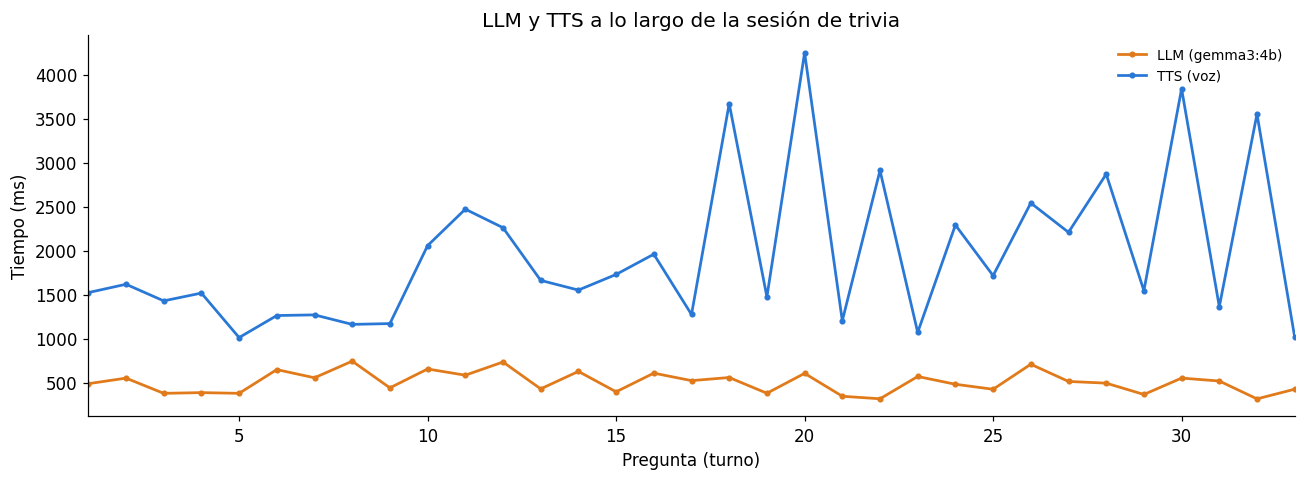

LLM: promedio 507 ms | TTS: promedio 1953 ms


In [13]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["LLM"], color=NARANJA, lw=1.8, marker="o", ms=3, label="LLM (gemma3:4b)")
ax.plot(x, dft["TTS"], color=AZUL, lw=1.8, marker="o", ms=3, label="TTS (voz)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_xlim(1, len(dft))
ax.set_title("LLM y TTS a lo largo de la sesión de trivia")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print(f"LLM: promedio {dft['LLM'].mean():.0f} ms | TTS: promedio {dft['TTS'].mean():.0f} ms")

## 9. Estado emocional de Romeo durante la trivia (AEB)

Emoción y nivel que Romeo mostró en cada turno (su estado afectivo real, no una
cara por defecto de acertó/falló). Con el perfil **optimista** su base lo mantiene
en felicidad aunque el usuario esté neutral.

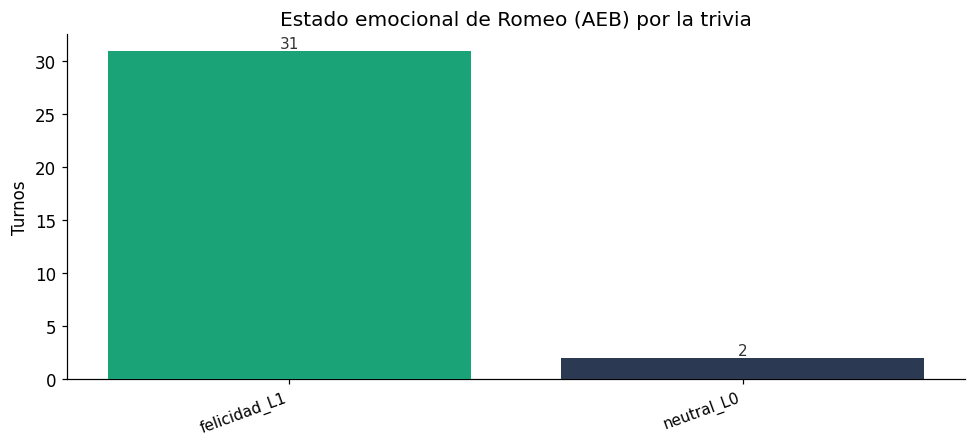

Emociones mostradas:
emocion
felicidad_L1    31
neutral_L0       2

Movimientos:
movimiento
ninguno    33


In [14]:
conteo = dft["emocion"].value_counts()
fig, ax = plt.subplots(figsize=(9,4.2))
colores = {"felicidad_L1":VERDE, "felicidad_L2":"#15c08a", "felicidad_L3":"#0e8f66",
           "neutral_L0":GRIS, "tristeza_L1":AZUL, "enojo_L1":ROJO}
cs = [colores.get(e, MORADO) for e in conteo.index]
ax.bar(range(len(conteo)), conteo.values, color=cs, zorder=3)
ax.set_xticks(range(len(conteo))); ax.set_xticklabels(conteo.index, rotation=20, ha="right", fontsize=10)
for i,v in enumerate(conteo.values):
    ax.text(i, v+0.2, str(v), ha="center", fontsize=10, color="#333")
ax.set_ylabel("Turnos"); ax.set_title("Estado emocional de Romeo (AEB) por la trivia")
plt.tight_layout(); plt.show()
print("Emociones mostradas:"); print(conteo.to_string())
mov = dft["movimiento"].value_counts()
print("\nMovimientos:"); print(mov.to_string())

## 10. Recursos de la Raspberry Pi (de inicio a fin)

CPU total, proceso de cámara (FER), **temperatura real** y RAM durante la sesión.
En esta corrida la temperatura **sí se capturó** (lectura de `thermal_zone0`).

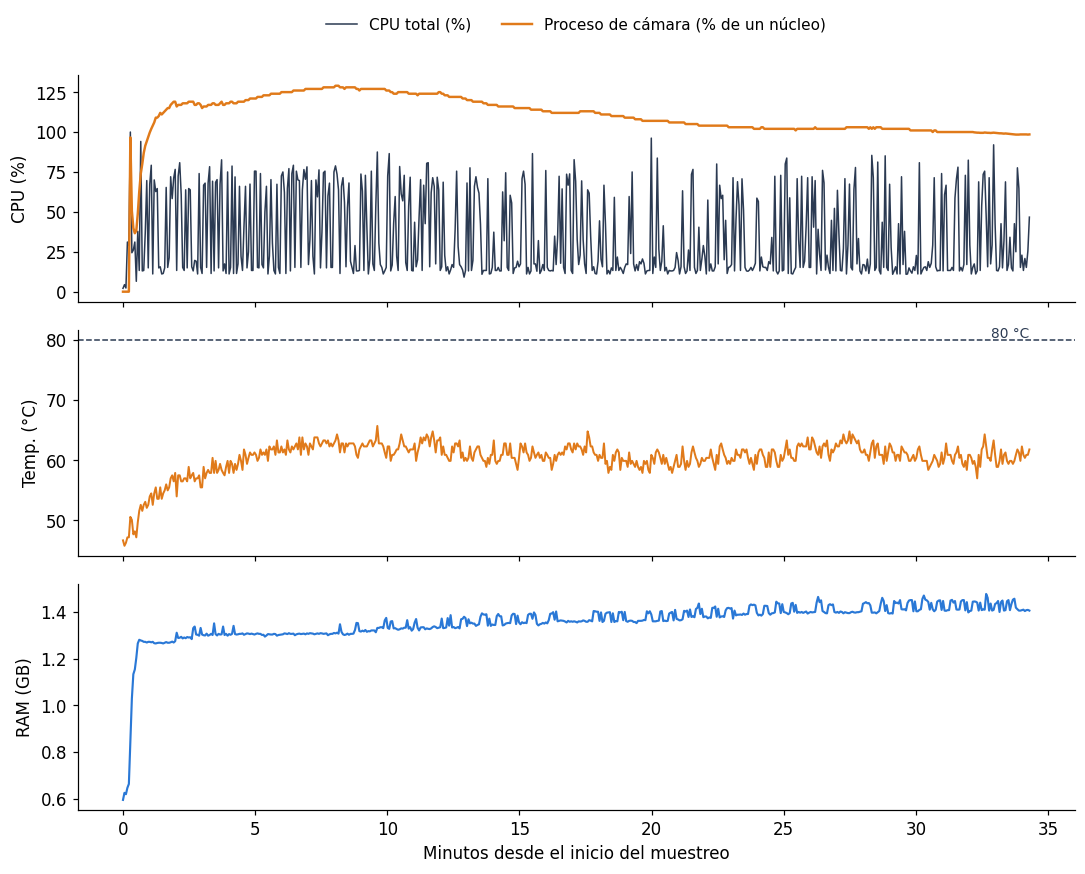

Recursos:
  CPU total:  mediana 17.4%  max 100.0%
  CPU camara: mediana 110.0%  max 129.0%
  Temp:       mediana 60.9°C  max 65.7°C
  RAM usada:  mediana 1396 MB  max 1512 MB


In [15]:
ram_gb = sis["ram_usada_mb"] / 1024

fig, axs = plt.subplots(3, 1, figsize=(10,8), sharex=True)
# (1) CPU total + camara
axs[0].plot(sis["min"], sis["cpu_total_pct"], color=GRIS, lw=1, label="CPU total (%)")
axs[0].plot(sis["min"], sis["cpu_camara_pct"], color=NARANJA, lw=1.6, label="Proceso de cámara (% de un núcleo)")
axs[0].set_ylabel("CPU (%)")
axs[0].legend(loc="upper center", bbox_to_anchor=(0.5,1.32), ncol=2, frameon=False, fontsize=10)
# (2) Temperatura real
axs[1].plot(sis["min"], sis["temp_c"], color=NARANJA, lw=1.3)
axs[1].axhline(80, color=GRIS, ls="--", lw=1)
axs[1].text(sis["min"].max(), 80.4, "80 °C", ha="right", fontsize=9, color=GRIS)
axs[1].set_ylabel("Temp. (°C)")
# (3) RAM
axs[2].plot(sis["min"], ram_gb, color=AZUL, lw=1.4)
axs[2].set_ylabel("RAM (GB)")
axs[2].set_xlabel("Minutos desde el inicio del muestreo")
plt.tight_layout(); plt.show()

print("Recursos:")
print(f"  CPU total:  mediana {sis['cpu_total_pct'].median():.1f}%  max {sis['cpu_total_pct'].max():.1f}%")
print(f"  CPU camara: mediana {sis['cpu_camara_pct'].median():.1f}%  max {sis['cpu_camara_pct'].max():.1f}%")
print(f"  Temp:       mediana {sis['temp_c'].median():.1f}°C  max {sis['temp_c'].max():.1f}°C")
print(f"  RAM usada:  mediana {sis['ram_usada_mb'].median():.0f} MB  max {sis['ram_usada_mb'].max():.0f} MB")

## 11. Tabla resumen (trivia)

In [16]:
def prom1(s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return round(s.mean(),1) if len(s) else np.nan

tabla = []
for nombre, serie, unidad, nodo in [
    ("STT (voz→texto)", dft["STT"], "ms", "communication / Pi"),
    ("SER (emoción voz)", dft["SER"], "ms", "communication / Pi"),
    ("TER (emoción texto)", dft["TER"], "ms", "communication / Pi"),
    ("Ida-vuelta percepción", dft["ida_vuelta"], "ms", "Pi ↔ servidor"),
    ("Afectiva PULSE+ROSE+AEB", dft["afectiva"], "ms", "orchestrator / Pi"),
    ("Respuesta LLM", dft["t_llm_ms"] if "t_llm_ms" in dft else dft["LLM"], "ms", "orchestrator / Pi→PC"),
    ("Síntesis TTS", dft["TTS"], "ms", "communication / PC"),
    ("Ventana FER", dft["FER"], "ms", "expression / Pi"),
    ("Tokens de salida", turnos["tokens_salida"], "tokens", "orchestrator"),
    ("CPU total Pi", sis["cpu_total_pct"], "%", "Raspberry"),
    ("CPU cámara/FER", sis["cpu_camara_pct"], "%", "expression"),
    ("Temperatura Pi", sis["temp_c"], "°C", "Raspberry"),
    ("RAM usada Pi", sis["ram_usada_mb"], "MB", "Raspberry"),
]:
    tabla.append([nombre, prom1(serie), unidad, nodo])
df = pd.DataFrame(tabla, columns=["Indicador","Promedio","Unidad","Nodo / máquina"])
print("Coincidencia Rocha vs IA: 19/33 = 58%\n")
df

Coincidencia Rocha vs IA: 19/33 = 58%



,Indicador,Promedio,Unidad,Nodo / máquina
0,STT (voz→texto),90.5,ms,communication / Pi
1,SER (emoción voz),213.3,ms,communication / Pi
2,TER (emoción texto),20.4,ms,communication / Pi
3,Ida-vuelta percepción,393.6,ms,Pi ↔ servidor
4,Afectiva PULSE+ROSE+AEB,8481.8,ms,orchestrator / Pi
5,Respuesta LLM,507.1,ms,orchestrator / Pi→PC
6,Síntesis TTS,1953.3,ms,communication / PC
7,Ventana FER,30569.7,ms,expression / Pi
8,Tokens de salida,36.0,tokens,orchestrator
9,CPU total Pi,34.0,%,Raspberry
